# Notebook 3: Transformer-Based Models
## mBERT · IndicBERT · XLM-R

**Input:** `data/train.csv`, `data/val.csv`, `data/test.csv`  
**Framework:** HuggingFace Transformers + PyTorch  
**Task:** Fine-tune multilingual models for Hinglish sentiment classification

> **GPU recommended.** Runtime → Change runtime type → T4 GPU (Google Colab).

## 0. Install & Imports

In [ ]:
# !pip install transformers datasets accelerate evaluate torch scikit-learn pandas

In [ ]:
import os, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
)
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')

LABEL_NAMES = ['negative', 'neutral', 'positive']
NUM_LABELS  = 3
os.makedirs('models/transformers', exist_ok=True)
sns.set_theme(style='whitegrid')
print('Imports ✓')

Device : cuda
GPU    : Tesla T4
Imports ✓


## 1. Configuration

In [ ]:
# ── Hyperparameters ───────────────────────────────────────────────────────────
# CONFIG = {
#     'max_len'      : 128,
#     'batch_size'   : 16,
#     'epochs'       : 4,
#     'lr'           : 2e-5,
#     'weight_decay' : 0.01,
#     'warmup_ratio' : 0.1,
#     'seed'         : 42,
# }

# # ── Model zoo (choose which to run) ─────────────────────────────────────────
# MODEL_ZOO = {
#     'mBERT'     : 'bert-base-multilingual-cased',
#     'IndicBERT' : 'ai4bharat/indic-bert',
#     'XLM-R'     : 'xlm-roberta-base',
# }

# # Set seed for reproducibility
# torch.manual_seed(CONFIG['seed'])
# np.random.seed(CONFIG['seed'])
# print('Config ready ✓')

In [ ]:
# First verify GPU
import torch
assert torch.cuda.is_available(), "NO GPU — go to Runtime > Change runtime type > T4 GPU"
print(f"GPU: {torch.cuda.get_device_name(0)}")

EXPERIMENTS = [
    {
        'model_name': 'bert-base-multilingual-cased',
        'short_name': 'mBERT',
        'epochs': 8,
        'batch_size': 32,
        'lr': 3e-5,
        'max_len': 128,
        'freeze_base': False,
    },
    {
        'model_name': 'google/muril-base-cased',
        'short_name': 'MuRIL',
        'epochs': 8,
        'batch_size': 32,
        'lr': 3e-5,
        'max_len': 128,
        'freeze_base': False,
    },
    {
        'model_name': 'xlm-roberta-base',
        'short_name': 'XLM-R',
        'epochs': 8,
        'batch_size': 32,
        'lr': 3e-5,
        'max_len': 128,
        'freeze_base': False,
    },
]

GPU: Tesla T4


## 2. Dataset & DataLoader

In [ ]:
# ── Load CSVs ────────────────────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

train_df = pd.read_csv('/content/drive/MyDrive/data/train.csv').dropna()
val_df   = pd.read_csv('/content/drive/MyDrive/data/val.csv').dropna()
test_df  = pd.read_csv('/content/drive/MyDrive/data/test.csv').dropna()
print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')

Mounted at /content/drive
Train: 3994 | Val: 856 | Test: 856


In [ ]:
class HinglishDataset(Dataset):
    """PyTorch Dataset for tokenised Hinglish text."""
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts     = texts.reset_index(drop=True)
        self.labels    = labels.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            str(self.texts[idx]),
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt',
        )
        return {
            'input_ids'     : encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'label'         : torch.tensor(self.labels[idx], dtype=torch.long),
        }

print('Dataset class defined ✓')

Dataset class defined ✓


## 3. Training & Evaluation Functions

In [ ]:
def train_epoch(model, loader, optimizer, scheduler, device):
    model.train()
    total_loss, preds_all, labels_all = 0, [], []
    for batch in loader:
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attn_mask = batch['attention_mask'].to(device)
        labels    = batch['label'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        preds  = outputs.logits.argmax(dim=-1).cpu().numpy()
        preds_all.extend(preds)
        labels_all.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    acc = accuracy_score(labels_all, preds_all)
    f1  = f1_score(labels_all, preds_all, average='weighted')
    return avg_loss, acc, f1


def evaluate(model, loader, device):
    model.eval()
    total_loss, preds_all, labels_all = 0, [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attn_mask = batch['attention_mask'].to(device)
            labels    = batch['label'].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attn_mask, labels=labels)
            total_loss += outputs.loss.item()
            preds = outputs.logits.argmax(dim=-1).cpu().numpy()
            preds_all.extend(preds)
            labels_all.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    acc = accuracy_score(labels_all, preds_all)
    f1  = f1_score(labels_all, preds_all, average='weighted')
    return avg_loss, acc, f1, preds_all, labels_all


def plot_training_curves(history, model_name):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    metrics = ['loss', 'acc', 'f1']
    titles  = ['Loss', 'Accuracy', 'F1 (weighted)']
    for ax, m, t in zip(axes, metrics, titles):
        ax.plot(history[f'train_{m}'], label='train', marker='o')
        ax.plot(history[f'val_{m}'],   label='val',   marker='s')
        ax.set_title(f'{model_name} — {t}')
        ax.set_xlabel('Epoch')
        ax.legend()
    plt.tight_layout()
    plt.savefig(f'{model_name.replace(" ","_")}_training_curves.png')
    plt.show()

print('Training functions defined ✓')

Training functions defined ✓


## 4. Fine-Tune Each Model

In [ ]:
def run_model(model_name, model_checkpoint, config, train_df, val_df, test_df, device):
    print(f'\n{"="*60}')
    print(f'  Model: {model_name} ({model_checkpoint})')
    print(f'{"="*60}')

    # ── Tokenizer & datasets ──────────────────────────────────────────────────
    tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

    train_ds = HinglishDataset(train_df['text'], train_df['label'], tokenizer, config['max_len'])
    val_ds   = HinglishDataset(val_df['text'],   val_df['label'],   tokenizer, config['max_len'])
    test_ds  = HinglishDataset(test_df['text'],  test_df['label'],  tokenizer, config['max_len'])

    train_loader = DataLoader(train_ds, batch_size=config['batch_size'], shuffle=True,  num_workers=2)
    val_loader   = DataLoader(val_ds,   batch_size=config['batch_size'], shuffle=False, num_workers=2)
    test_loader  = DataLoader(test_ds,  batch_size=config['batch_size'], shuffle=False, num_workers=2)

    # ── Model ────────────────────────────────────────────────────────────────
    model = AutoModelForSequenceClassification.from_pretrained(
        model_checkpoint, num_labels=NUM_LABELS, ignore_mismatched_sizes=True
    ).to(device)

    # ── Optimizer & Scheduler ─────────────────────────────────────────────────
    total_steps  = len(train_loader) * config['epochs']
    warmup_steps = int(total_steps * config['warmup_ratio'])

    optimizer = AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps
    )

    # ── Training loop ─────────────────────────────────────────────────────────
    history = {k: [] for k in ['train_loss','train_acc','train_f1',
                                'val_loss',  'val_acc',  'val_f1']}
    best_val_f1, best_epoch = 0, 0

    for epoch in range(1, config['epochs'] + 1):
        tr_loss, tr_acc, tr_f1 = train_epoch(model, train_loader, optimizer, scheduler, device)
        vl_loss, vl_acc, vl_f1, _, _ = evaluate(model, val_loader, device)

        history['train_loss'].append(tr_loss); history['train_acc'].append(tr_acc); history['train_f1'].append(tr_f1)
        history['val_loss'].append(vl_loss);   history['val_acc'].append(vl_acc);   history['val_f1'].append(vl_f1)

        print(f'  Epoch {epoch}/{config["epochs"]} | '
              f'Train Loss={tr_loss:.4f} Acc={tr_acc:.4f} F1={tr_f1:.4f} | '
              f'Val Loss={vl_loss:.4f} Acc={vl_acc:.4f} F1={vl_f1:.4f}')

        # Save best checkpoint
        if vl_f1 > best_val_f1:
            best_val_f1 = vl_f1
            best_epoch  = epoch
            model.save_pretrained(f'models/transformers/{model_name}')
            tokenizer.save_pretrained(f'models/transformers/{model_name}')

    print(f'  Best Val F1={best_val_f1:.4f} at epoch {best_epoch}')

    # ── Load best model & evaluate on test set ─────────────────────────────
    best_model = AutoModelForSequenceClassification.from_pretrained(
        f'models/transformers/{model_name}'
    ).to(device)
    _, test_acc, test_f1, test_preds, test_labels = evaluate(best_model, test_loader, device)

    print(f'  TEST → Acc={test_acc:.4f} | F1={test_f1:.4f}')
    print(classification_report(test_labels, test_preds, target_names=LABEL_NAMES))

    # Confusion matrix
    cm = confusion_matrix(test_labels, test_preds)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=LABEL_NAMES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{model_name} — Test Confusion Matrix')
    plt.tight_layout()
    plt.savefig(f'{model_name.replace(" ","_")}_confusion_matrix.png')
    plt.show()

    # Training curves
    plot_training_curves(history, model_name)

    return {
        'Model'   : model_name,
        'Val F1'  : round(best_val_f1, 4),
        'Test Acc': round(test_acc, 4),
        'Test F1' : round(test_f1, 4),
    }


print('run_model() defined ✓')

run_model() defined ✓



Running: mBERT (bert-base-multilingual-cased)

  Model: mBERT (bert-base-multilingual-cased)


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

... (13 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Epoch 7/8 | Train Loss=0.0336 Acc=0.9905 F1=0.9905 | Val Loss=0.8165 Acc=0.8540 F1=0.8537
  Epoch 8/8 | Train Loss=0.0230 Acc=0.9937 F1=0.9937 | Val Loss=0.8074 Acc=0.8633 F1=0.8633
  Best Val F1=0.8635 at epoch 6


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  TEST → Acc=0.8657 | F1=0.8656
              precision    recall  f1-score   support

    negative       0.88      0.90      0.89       273
     neutral       0.85      0.85      0.85       283
    positive       0.87      0.85      0.86       300

    accuracy                           0.87       856
   macro avg       0.87      0.87      0.87       856
weighted avg       0.87      0.87      0.87       856



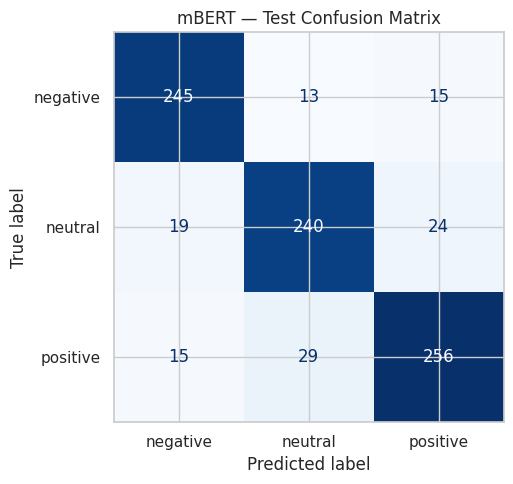

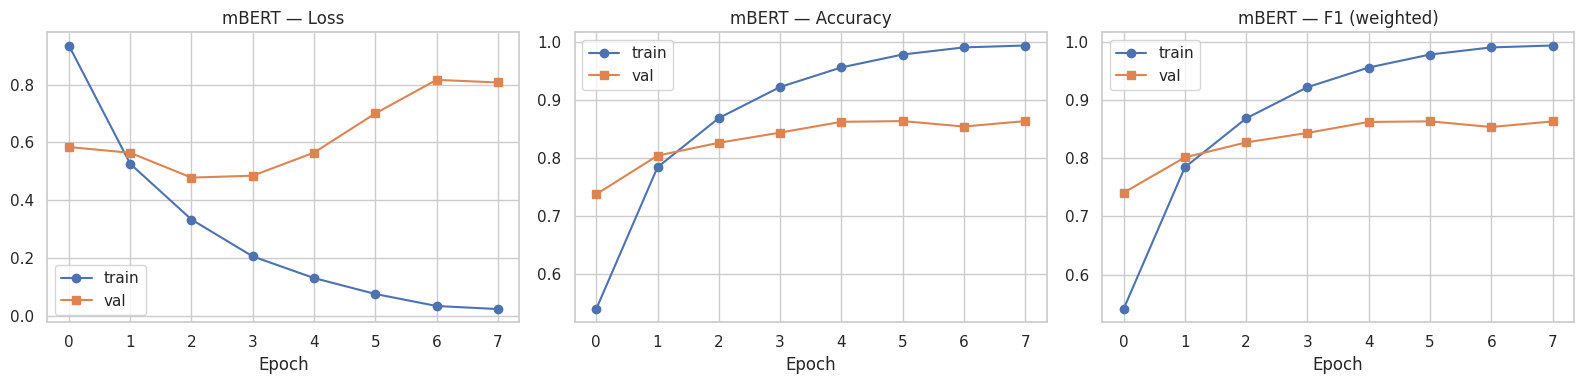


Running: MuRIL (google/muril-base-cased)

  Model: MuRIL (google/muril-base-cased)


config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/953M [00:00<?, ?B/s]

... (14 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Best Val F1=0.8592 at epoch 8


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  TEST → Acc=0.8633 | F1=0.8633
              precision    recall  f1-score   support

    negative       0.88      0.89      0.88       273
     neutral       0.85      0.85      0.85       283
    positive       0.87      0.85      0.86       300

    accuracy                           0.86       856
   macro avg       0.86      0.86      0.86       856
weighted avg       0.86      0.86      0.86       856



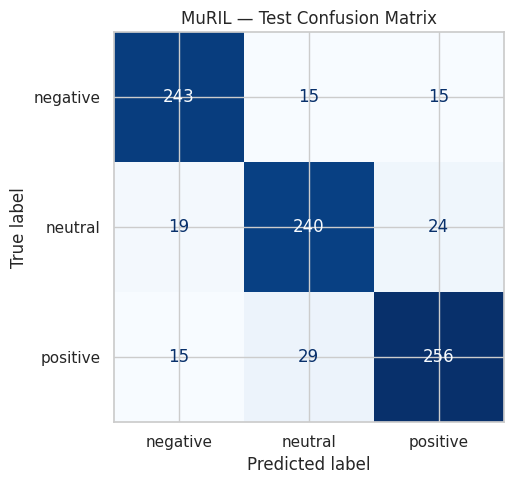

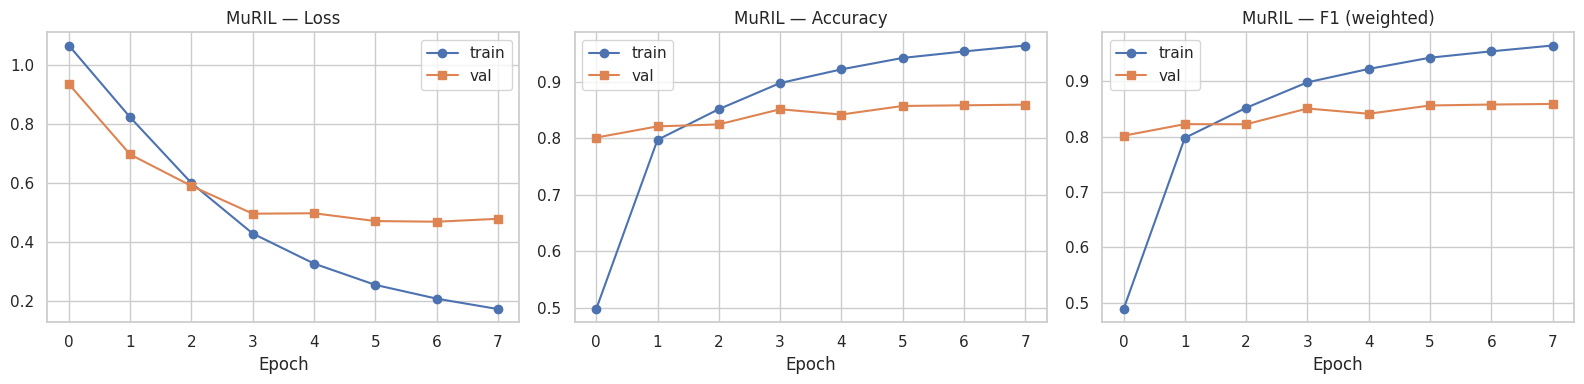


Running: XLM-R (xlm-roberta-base)

  Model: XLM-R (xlm-roberta-base)


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

... (11 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Epoch 7/8 | Train Loss=0.1945 Acc=0.9324 F1=0.9324 | Val Loss=0.6142 Acc=0.8458 F1=0.8457
  Epoch 8/8 | Train Loss=0.1474 Acc=0.9522 F1=0.9522 | Val Loss=0.6031 Acc=0.8470 F1=0.8469
  Best Val F1=0.8543 at epoch 6


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  TEST → Acc=0.8318 | F1=0.8323
              precision    recall  f1-score   support

    negative       0.90      0.84      0.87       273
     neutral       0.82      0.81      0.81       283
    positive       0.79      0.85      0.82       300

    accuracy                           0.83       856
   macro avg       0.84      0.83      0.83       856
weighted avg       0.83      0.83      0.83       856



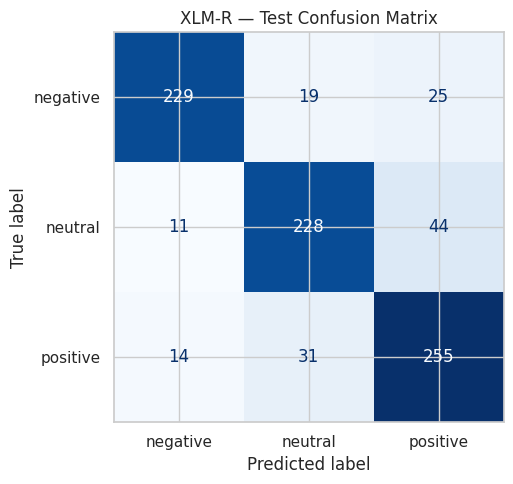

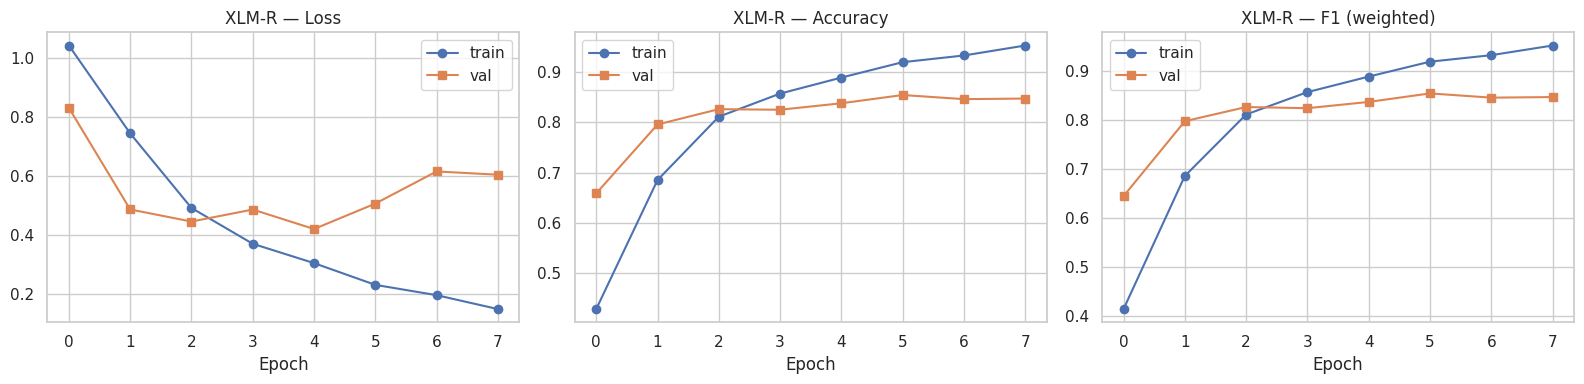


=== Transformer Results ===


,Model,Val F1,Test Acc,Test F1
0,mBERT,0.8635,0.8657,0.8656
1,MuRIL,0.8592,0.8633,0.8633
2,XLM-R,0.8543,0.8318,0.8323


In [ ]:
transformer_results = []

for exp in EXPERIMENTS:
    print(f"\nRunning: {exp['short_name']} ({exp['model_name']})")
    result = run_model(
        model_name       = exp['short_name'],
        model_checkpoint = exp['model_name'],
        config = {
            'epochs':       exp['epochs'],
            'batch_size':   exp['batch_size'],
            'lr':           exp['lr'],
            'max_len':      exp['max_len'],
            'warmup_ratio': 0.1,
            'weight_decay': 0.01,
        },
        train_df = train_df,
        val_df   = val_df,
        test_df  = test_df,
        device   = DEVICE
    )
    transformer_results.append(result)

trans_df = pd.DataFrame(transformer_results).sort_values('Test F1', ascending=False)
print('\n=== Transformer Results ===')
trans_df

In [ ]:
from huggingface_hub import login

login()

In [ ]:
# # ── Run all transformer models ────────────────────────────────────────────────
# # ⚠️  This cell can take 20–60 min per model on GPU.
# # To run only one model: MODEL_ZOO = {'mBERT': 'bert-base-multilingual-cased'}

# transformer_results = []

# for model_name, checkpoint in MODEL_ZOO.items():
#     result = run_model(
#         model_name, checkpoint, CONFIG,
#         train_df, val_df, test_df, DEVICE
#     )
#     transformer_results.append(result)

# trans_df = pd.DataFrame(transformer_results).sort_values('Test F1', ascending=False)
# print('\n=== Transformer Results ===')
# trans_df

In [ ]:
transformer_results = []

for exp in EXPERIMENTS:
    print(f"\nRunning: {exp['short_name']} ({exp['model_name']})")
    result = run_model(
        model_name  = exp['short_name'],
        checkpoint  = exp['model_name'],
        config      = {
            'epochs':     exp['epochs'],
            'batch_size': exp['batch_size'],
            'lr':         exp['lr'],
            'max_len':    exp['max_len'],
        },
        train_df = train_df,
        val_df   = val_df,
        test_df  = test_df,
        device   = DEVICE
    )
    transformer_results.append(result)

trans_df = pd.DataFrame(transformer_results).sort_values('Test F1', ascending=False)
print('\n=== Transformer Results ===')
trans_df


Running: mBERT (bert-base-multilingual-cased)


TypeError: run_model() got an unexpected keyword argument 'checkpoint'

In [ ]:
# ── Save results ──────────────────────────────────────────────────────────────
trans_df.to_csv('/content/drive/MyDrive/data/transformer_results.csv', index=False)
print('Saved → transformer_results.csv ✓')
print('\n➡ Proceed to Notebook 4 for model comparison & inference.')